<a href="https://colab.research.google.com/github/MitchellParks29/BioinformaticsProject/blob/main/BioinformaticsProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Data Processing


In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

expression = pd.read_csv(
    "GSE2034_normalized_expression.csv",
    index_col=0
)
metadata = pd.read_csv("GSE2034_metadata.csv")
X = expression.T
print(df.shape)
#display(df.head())

print(metadata.shape)
display(metadata.head())

(22283, 286)
(286, 29)


,title,geo_accession,status,submission_date,last_update_date,type,channel_count,source_name_ch1,organism_ch1,characteristics_ch1,...,contact_city,contact_state,contact_zip/postal_code,contact_country,supplementary_file,data_row_count,relation,relation.1,"bone relapses (1=yes, 0=no):ch1",sample_id
0,Wang4812_JA_277,GSM36777,Public on Feb 23 2005,Dec 03 2004,May 31 2013,RNA,1,Breast,Homo sapiens,"bone relapses (1=yes, 0=no): 0",...,San Diego,CA,92121,USA,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM36nn...,22283,Reanalyzed by: GSE47561,NaN,0,GSM36777
1,Wang4813_JA_278,GSM36778,Public on Feb 23 2005,Dec 03 2004,May 31 2013,RNA,1,Breast,Homo sapiens,"bone relapses (1=yes, 0=no): 0",...,San Diego,CA,92121,USA,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM36nn...,22283,Reanalyzed by: GSE47561,NaN,0,GSM36778
2,Wang4630_JA798@C,GSM36779,Public on Feb 23 2005,Dec 03 2004,May 31 2013,RNA,1,Breast,Homo sapiens,"bone relapses (1=yes, 0=no): 0",...,San Diego,CA,92121,USA,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM36nn...,22283,Reanalyzed by: GSE47561,NaN,0,GSM36779
3,Wang4889_JA_846@2,GSM36780,Public on Feb 23 2005,Dec 03 2004,May 31 2013,RNA,1,Breast,Homo sapiens,"bone relapses (1=yes, 0=no): 0",...,San Diego,CA,92121,USA,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM36nn...,22283,Reanalyzed by: GSE47561,NaN,0,GSM36780
4,Wang4857_JA_765@2,GSM36781,Public on Feb 23 2005,Dec 03 2004,May 31 2013,RNA,1,Breast,Homo sapiens,"bone relapses (1=yes, 0=no): 0",...,San Diego,CA,92121,USA,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM36nn...,22283,Reanalyzed by: GSE47561,NaN,0,GSM36781


In [11]:
print( X.isnull().sum().sum())
print(X.index.duplicated().sum())

0
0


In [16]:
gene_variance = X.var(axis=0)
top_genes = gene_variance.nlargest(2000).index
X_filtered = X[top_genes]

In [15]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_filtered)

(286, 2000)


# PCA

In [20]:
from sklearn.decomposition import PCA
pca = PCA(n_components=25)
X_pca = pca.fit_transform(X_scaled)
pca_df = pd.DataFrame(
    X_pca,
    columns=[f"PC{i+1}" for i in range(25)],
    index=X.index
)

print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

print(
    "Total explained variance:",
    pca.explained_variance_ratio_.sum()
)

Explained variance ratio:
[0.14746978 0.09853817 0.0712955  0.05415023 0.03427783 0.02816188
 0.02778179 0.01837277 0.01641813 0.01355172 0.01288274 0.01217725
 0.01106011 0.01047234 0.00934213 0.0087415  0.00852345 0.00777733
 0.00768799 0.00724791 0.00703777 0.00660947 0.00621489 0.00607548
 0.00578548]
Total explained variance: 0.6376536170454025


# Clustering

## NON PCA Cluster


In [25]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
kmeans = KMeans(
    n_clusters=2,
    random_state=100,
    n_init=15
)

labels = kmeans.fit_predict(X_scaled)

silhouette = silhouette_score(
    X_scaled,
    labels
)

results=({
    "Clusters": 2,
    "Inertia": kmeans.inertia_,
    "Silhouette": silhouette
})

print(results)

{'Clusters': 2, 'Inertia': 508171.8903314621, 'Silhouette': np.float64(0.12086143817880156)}


## PCA Cluster


In [35]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
kmeans_PCA = KMeans(
    n_clusters=2,
    random_state=100,
    n_init=15
)

labels_PCA = kmeans_PCA.fit_predict(pca_df)

silhouette = silhouette_score(
    pca_df,
    labels
)

results_PCA=({
    "Clusters": 2,
    "Inertia": kmeans.inertia_,
    "Silhouette": silhouette
})

print(results_PCA)

{'Clusters': 2, 'Inertia': 301092.0277881534, 'Silhouette': np.float64(0.1824428292334076)}


Number of matched patients: 286
                PC1        PC2        PC3        PC4        PC5        PC6  \
GSM36777  14.399686  12.760693   5.326829   5.205836   3.635017  -4.267312   
GSM36778   2.968367 -12.142443 -24.366491 -10.113924   9.170587  -7.891957   
GSM36779  20.856946 -21.374715  12.405489 -10.094042 -16.099940  -5.389794   
GSM36780 -11.358540  -6.735268  21.874423  -5.202734   6.252988  13.428598   
GSM36781 -19.420950 -22.335487  13.744684 -16.200700   3.127888   2.389303   

                PC7        PC8        PC9       PC10  ...      PC18      PC19  \
GSM36777   4.550374   6.881445   3.482520   2.035238  ... -5.185295 -3.953480   
GSM36778  -9.096496   0.178347   2.922382  -6.886645  ... -0.372864  0.440893   
GSM36779  13.167791  13.483351 -18.171116 -12.166898  ... -3.526614  2.870053   
GSM36780 -15.750222   2.714890  -3.472989  -3.917835  ...  5.439670 -1.230606   
GSM36781  -9.737721  -3.538017   1.557787   5.285231  ... -0.825070 -3.801614   

            

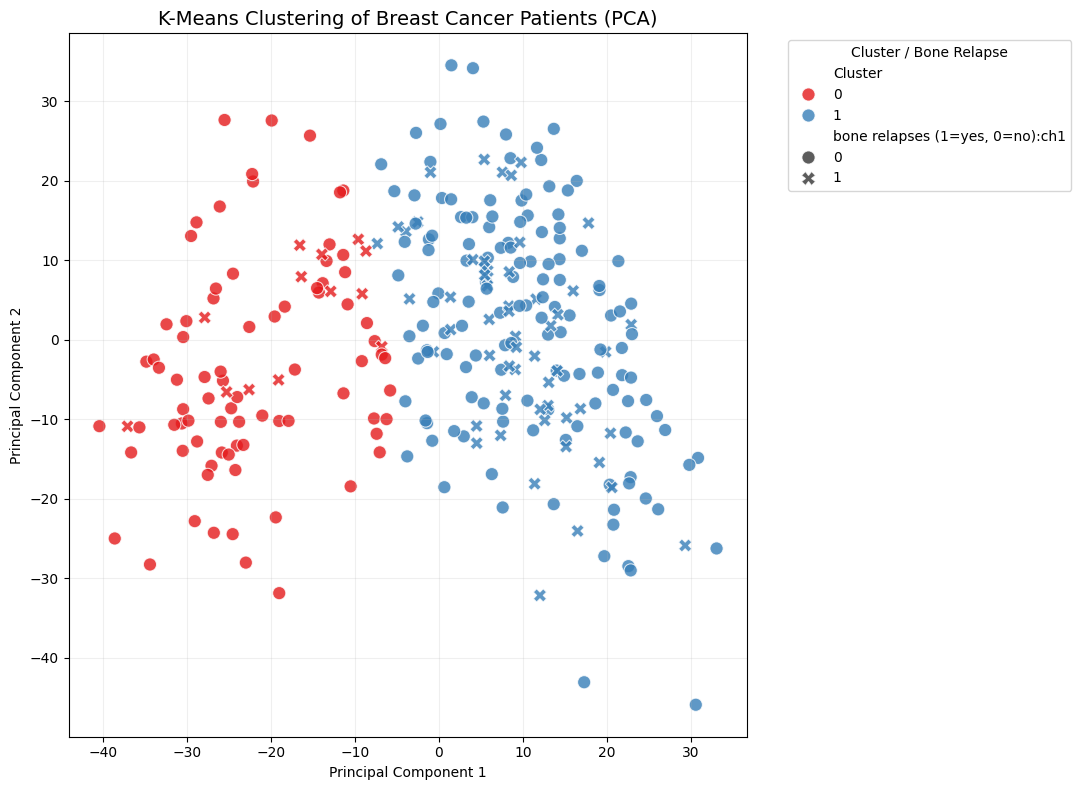

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pca_df["Cluster"] = labels_PCA
pca_df.index = (
    pca_df.index
    .str.replace(".CEL.gz", "", regex=False)
)

recurrence_col = "bone relapses (1=yes, 0=no):ch1"
metadata["sample_id"] = (
    metadata["sample_id"]
    .astype(str)
    .str.strip()
)

clinical = metadata.set_index("sample_id")[recurrence_col]
plot_df = pca_df.join(
    clinical,
    how="inner"
)

print("Number of matched patients:", len(plot_df))
print(plot_df.head())
plt.figure(figsize=(11, 8))
sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    style=recurrence_col,
    palette="Set1",
    s=90,
    alpha=0.8
)
plt.title(
    "K-Means Clustering of Breast Cancer Patients (PCA)",
    fontsize=10
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend(
    title="Cluster / Bone Relapse",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()